# Dijkstra's Algorithm: Adjacency Matrix + Array Priority Queue

This notebook is for **SC2001 Lab 2, Part (a)**.

We implement Dijkstra's algorithm using:

- an **adjacency matrix** for the graph, and
- an **array-style priority queue**, where we scan all unvisited vertices to find the next closest one.

This version is easy to understand, but it has `O(|V|^2)` time complexity.

## 1. Imports

In [1]:
from math import inf
from random import Random
from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt

NO_EDGE = inf

## 2. Dijkstra Implementation

The priority queue is represented by the `visited` list.

To extract the next vertex, we scan all vertices and choose the unvisited vertex with the smallest known distance.

In [2]:
def find_closest_unvisited(distance, visited):
    """Return the unvisited vertex with the smallest known distance."""
    closest_vertex = None
    closest_distance = inf

    for vertex in range(len(distance)):
        if not visited[vertex] and distance[vertex] < closest_distance:
            closest_vertex = vertex
            closest_distance = distance[vertex]

    return closest_vertex


def check_graph(graph, source):
    """Check for common input mistakes before running the algorithm."""
    number_of_vertices = len(graph)

    if source < 0 or source >= number_of_vertices:
        raise ValueError("source must be a valid vertex index")

    for row in graph:
        if len(row) != number_of_vertices:
            raise ValueError("graph must be a square adjacency matrix")

        for weight in row:
            if weight != NO_EDGE and weight < 0:
                raise ValueError("Dijkstra's algorithm cannot use negative weights")


def dijkstra(graph, source):
    """Find shortest paths from source to all vertices in graph."""
    number_of_vertices = len(graph)
    check_graph(graph, source)

    distance = [inf] * number_of_vertices
    previous = [None] * number_of_vertices
    visited = [False] * number_of_vertices

    distance[source] = 0

    for _ in range(number_of_vertices):
        current = find_closest_unvisited(distance, visited)

        if current is None:
            break

        visited[current] = True

        for neighbour in range(number_of_vertices):
            weight = graph[current][neighbour]

            if visited[neighbour] or weight == NO_EDGE:
                continue

            new_distance = distance[current] + weight

            if new_distance < distance[neighbour]:
                distance[neighbour] = new_distance
                previous[neighbour] = current

    return distance, previous


def build_path(previous, source, destination):
    """Rebuild one shortest path from source to destination."""
    path = []
    current = destination

    while current is not None:
        path.append(current)

        if current == source:
            path.reverse()
            return path

        current = previous[current]

    return []

## 3. Run a Small Example

`NO_EDGE` means there is no direct edge between two vertices.

In [3]:
graph = [
    [0, 10, 3, NO_EDGE, NO_EDGE],
    [NO_EDGE, 0, 1, 2, NO_EDGE],
    [NO_EDGE, 4, 0, 8, 2],
    [NO_EDGE, NO_EDGE, NO_EDGE, 0, 7],
    [NO_EDGE, NO_EDGE, NO_EDGE, 9, 0],
]

source = 0
distance, previous = dijkstra(graph, source)

print("Source vertex:", source)
print("Shortest distances:", distance)
print()

for destination in range(len(graph)):
    path = build_path(previous, source, destination)
    print(f"Path to {destination}: {path}")

Source vertex: 0
Shortest distances: [0, 7, 3, 9, 5]

Path to 0: [0]
Path to 1: [0, 2, 1]
Path to 2: [0, 2]
Path to 3: [0, 2, 1, 3]
Path to 4: [0, 2, 4]


## 4. Random Graph Generator

This helper creates a random directed graph as an adjacency matrix.

A simple chain is added first so every vertex is reachable from vertex `0`.

In [4]:
def make_random_matrix(number_of_vertices, density, seed):
    """Create a reachable directed graph as an adjacency matrix."""
    rng = Random(seed)
    graph = [[NO_EDGE] * number_of_vertices for _ in range(number_of_vertices)]

    for vertex in range(number_of_vertices):
        graph[vertex][vertex] = 0

    edges = set()

    for vertex in range(number_of_vertices - 1):
        graph[vertex][vertex + 1] = rng.randint(1, 20)
        edges.add((vertex, vertex + 1))

    possible_edges = number_of_vertices * (number_of_vertices - 1)
    target_edges = max(len(edges), int(possible_edges * density))

    while len(edges) < target_edges:
        start = rng.randrange(number_of_vertices)
        end = rng.randrange(number_of_vertices)

        if start == end or (start, end) in edges:
            continue

        graph[start][end] = rng.randint(1, 20)
        edges.add((start, end))

    return graph, len(edges)

## 5. Empirical Timing Helper

We run the algorithm several times and use the median time to reduce timing noise.

In [5]:
def time_one_graph(number_of_vertices, density, repeats, seed):
    graph, number_of_edges = make_random_matrix(number_of_vertices, density, seed)
    timings = []

    for _ in range(repeats):
        start_time = perf_counter()
        dijkstra(graph, source=0)
        end_time = perf_counter()
        timings.append(end_time - start_time)

    return number_of_edges, median(timings)


def benchmark_by_size(sizes, density=0.20, repeats=5):
    results = []

    for index, number_of_vertices in enumerate(sizes):
        number_of_edges, seconds = time_one_graph(
            number_of_vertices=number_of_vertices,
            density=density,
            repeats=repeats,
            seed=1000 + index,
        )

        results.append({
            "V": number_of_vertices,
            "E": number_of_edges,
            "density": number_of_edges / (number_of_vertices * (number_of_vertices - 1)),
            "seconds": seconds,
            "microseconds_per_V_squared": seconds * 1_000_000 / (number_of_vertices ** 2),
        })

    return results


def show_results(results):
    print("V\tE\tDensity\tSeconds\tMicroseconds / V^2")
    for row in results:
        print(
            f"{row['V']}\t{row['E']}\t{row['density']:.4f}\t"
            f"{row['seconds']:.6f}\t{row['microseconds_per_V_squared']:.4f}"
        )

## 6. Run Benchmark as `|V|` Increases

The expected theoretical growth is approximately quadratic: `O(|V|^2)`.

In [6]:
sizes = [50, 100, 200, 400, 800]
size_results = benchmark_by_size(sizes, density=0.20, repeats=5)
show_results(size_results)

V	E	Density	Seconds	Microseconds / V^2
50	490	0.2000	0.000354	0.1416
100	1980	0.2000	0.001581	0.1581
200	7960	0.2000	0.005866	0.1466
400	31920	0.2000	0.020103	0.1256
800	127840	0.2000	0.080165	0.1253


## 7. Visualise Runtime Growth

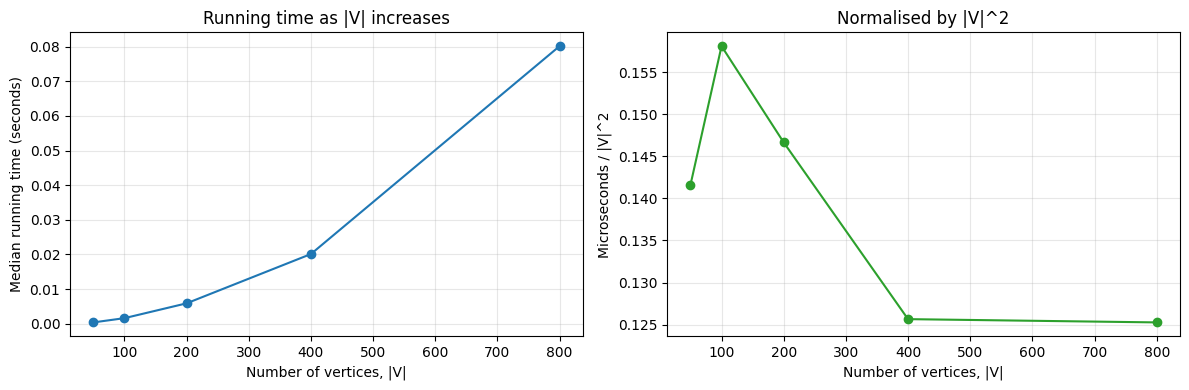

In [7]:
vertices = [row["V"] for row in size_results]
seconds = [row["seconds"] for row in size_results]
normalised = [row["microseconds_per_V_squared"] for row in size_results]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(vertices, seconds, marker="o")
plt.xlabel("Number of vertices, |V|")
plt.ylabel("Median running time (seconds)")
plt.title("Running time as |V| increases")
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(vertices, normalised, marker="o", color="tab:green")
plt.xlabel("Number of vertices, |V|")
plt.ylabel("Microseconds / |V|^2")
plt.title("Normalised by |V|^2")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Change `|E|` While Keeping `|V|` Fixed

For this matrix-based version, changing the number of actual edges does not change the main order of growth much, because each matrix row still has to be scanned.

In [8]:
fixed_vertices = 600
densities = [0.02, 0.20, 0.60]
density_results = []

for index, density in enumerate(densities):
    number_of_edges, seconds = time_one_graph(
        number_of_vertices=fixed_vertices,
        density=density,
        repeats=5,
        seed=2000 + index,
    )

    density_results.append({
        "density": density,
        "E": number_of_edges,
        "seconds": seconds,
    })

print("Density\tE\tSeconds")
for row in density_results:
    print(f"{row['density']:.2f}\t\t{row['E']}\t{row['seconds']:.6f}")

Density	E	Seconds
0.02		7188	0.037380
0.20		71880	0.045218
0.60		215640	0.053889


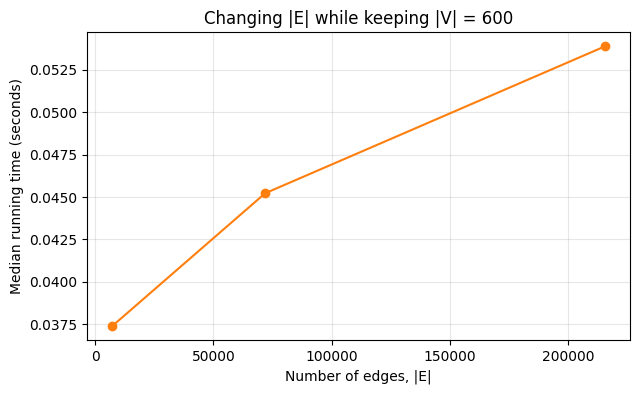

In [9]:
edge_counts = [row["E"] for row in density_results]
density_seconds = [row["seconds"] for row in density_results]

plt.figure(figsize=(7, 4))
plt.plot(edge_counts, density_seconds, marker="o", color="tab:orange")
plt.xlabel("Number of edges, |E|")
plt.ylabel("Median running time (seconds)")
plt.title(f"Changing |E| while keeping |V| = {fixed_vertices}")
plt.grid(True, alpha=0.3)
plt.show()

## 9. Time Complexity Summary

Let `|V|` be the number of vertices and `|E|` be the number of edges.

Using an array priority queue:

- Finding the next closest unvisited vertex takes `O(|V|)` time.
- This happens up to `|V|` times.
- So the priority queue work is `O(|V|^2)`.

Using an adjacency matrix:

- For each selected vertex, we scan the full matrix row.
- Each row has `|V|` possible neighbours.
- This also costs `O(|V|^2)` over the whole algorithm.

Therefore, the total time complexity is:

`O(|V|^2)`

The number of actual edges `|E|` does not strongly affect the main running time in this implementation because the adjacency matrix stores and scans possible edges, not only existing edges.

The space complexity is also `O(|V|^2)` because the adjacency matrix stores `|V| * |V|` entries.